# HS4002 Week 9

## Principal components analysis

A principal component is a linear combination of the variables. PCA reduces them to a smaller number of uncorrelated components.

The worked example uses five GSS variables: income, occupational prestige, education, number of children, and age. Each is scaled to mean 0 and SD 1. We fit the model with `sklearn.decomposition.PCA` and draw the scree plot with `plotnine`.


In [5]:
# !pip install pandas numpy plotnine scikit-learn statsmodels

import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')


In [6]:
raw_df = pd.read_csv("gss2022_mini2.csv")

chosen_variables = [
	'id', 'age', 'happy', 'yrlvmus', 'yrartxbt', 'yrmovie', 'yrcreat',
	'income16', 'prestg10', 'degree', 'biokids', 'educ'
]
df = raw_df[chosen_variables].copy()

income_map = {
	1: 500,    2: 2000,   3: 3500,   4: 4500,   5: 5500,   6: 6500,
	7: 7500,   8: 9000,   9: 11250,  10: 13750, 11: 16250, 12: 18750,
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 45000,
	19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 24: 140000,
	25: 160000, 26: 250000
}
df['income_cont'] = df['income16'].map(income_map)

df['binary_lvmus']  = (df['yrlvmus']  == 1).astype(int)
df['binary_artxbt'] = (df['yrartxbt'] == 1).astype(int)
df['binary_movie']  = (df['yrmovie']  == 1).astype(int)
df['binary_creat']  = (df['yrcreat']  == 1).astype(int)
df['ba_binary']     = (df['degree'] >= 3).astype(int)
df['happy_bin']     = (df['happy'] <= 2).astype(int)


# Steps

1. Choose the variables.
2. Scale each one to mean 0 and SD 1.
3. Fit the PCA.
4. Decide how many components to keep. The scree plot is the guide. There is no single rule.
5. Read the loadings.
6. Use the components in a plot or a regression.


## 1. Choose the variables

`income_cont` is income in dollars. `prestg10` is occupational prestige. `educ` is years of schooling. `biokids` is the number of children. `age` is age in years.


In [7]:
cols = ["income_cont", "prestg10", "educ", "biokids", "age"]
work = df.dropna(subset=cols).copy()
work[cols].describe().round(1)


,income_cont,prestg10,educ,biokids,age
count,1056.0,1056.0,1056.0,1056.0,1056.0
mean,86222.1,46.8,14.9,1.6,50.9
std,72378.7,13.3,2.7,1.5,17.3
min,500.0,17.0,2.0,0.0,18.0
25%,32500.0,36.0,13.0,0.0,36.0
50%,67500.0,47.0,15.0,2.0,51.0
75%,120000.0,59.0,16.0,2.0,66.0
max,250000.0,80.0,20.0,11.0,89.0


## 2--3. Scale, then fit

`StandardScaler` subtracts the mean and divides by the standard deviation. Without that step, income, which is measured in dollars, would dominate the first component.


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

prop = pca.explained_variance_ratio_
print(pd.DataFrame({
    "Standard deviation": pca.explained_variance_ ** 0.5,
    "Proportion of variance": prop,
    "Cumulative proportion": prop.cumsum(),
}, index=["PC1", "PC2", "PC3", "PC4", "PC5"]).T.round(3))


                          PC1    PC2    PC3    PC4    PC5
Standard deviation      1.368  1.127  0.882  0.781  0.689
Proportion of variance  0.374  0.254  0.155  0.122  0.095
Cumulative proportion   0.374  0.628  0.783  0.905  1.000


PC1 accounts for 37.4 per cent of the variance. The first two components together account for 62.8 per cent.


## 4. Loadings

In `sklearn`, each row of `pca.components_` is one component. Transposing it puts the variables in the rows, so each column is a component. A large loading means that variable defines that component.


In [9]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
)
print(loadings.round(3))


               PC1    PC2    PC3    PC4    PC5
income_cont  0.524  0.009 -0.517  0.676 -0.030
prestg10     0.592  0.095  0.042 -0.457 -0.656
educ         0.594 -0.112  0.209 -0.268  0.721
biokids     -0.098  0.710 -0.560 -0.351  0.223
age          0.109  0.689  0.612  0.373 -0.022


How would you describe PC1 and PC2?

PC1 loads on income, occupational prestige, and education. PC2 loads on number of children and age.


Answer: PC1 could be measuring socioeconomic status, while PC2 measures type of family unit.

## 5. How many components?

Look for an elbow in the scree plot: the point where adding another component buys little extra variance.


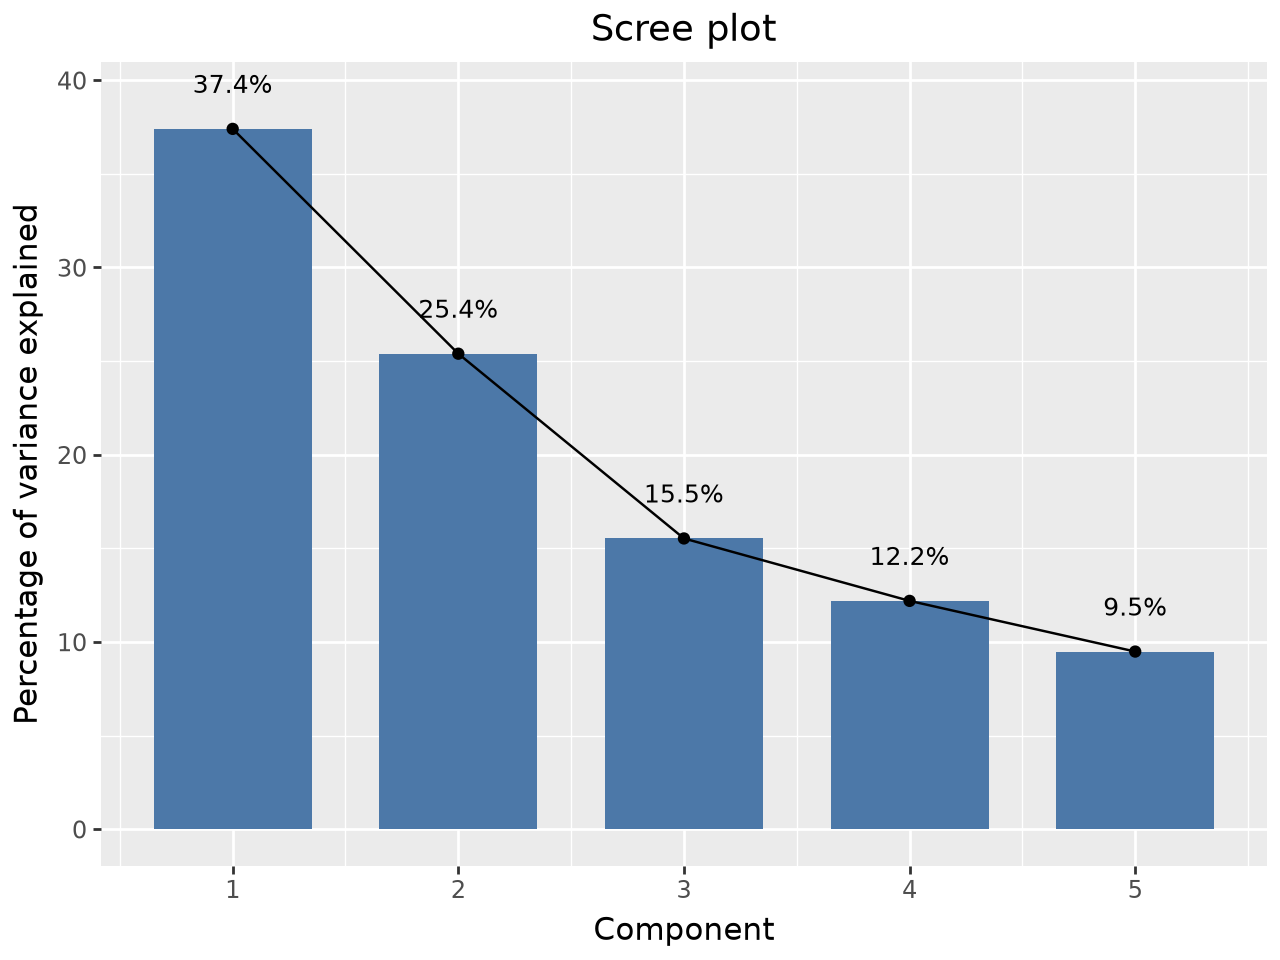

In [10]:
scree = pd.DataFrame({
    "component": range(1, 6),
    "percent": pca.explained_variance_ratio_ * 100,
})
scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(x="Component", y="Percentage of variance explained", title="Scree plot")
)


## 6. Use the components

The first two components locate each person in a plane. Colour the points by whether the person has a BA. A BA was not one of the five variables in the PCA, so the colour is a separate fact about the person.


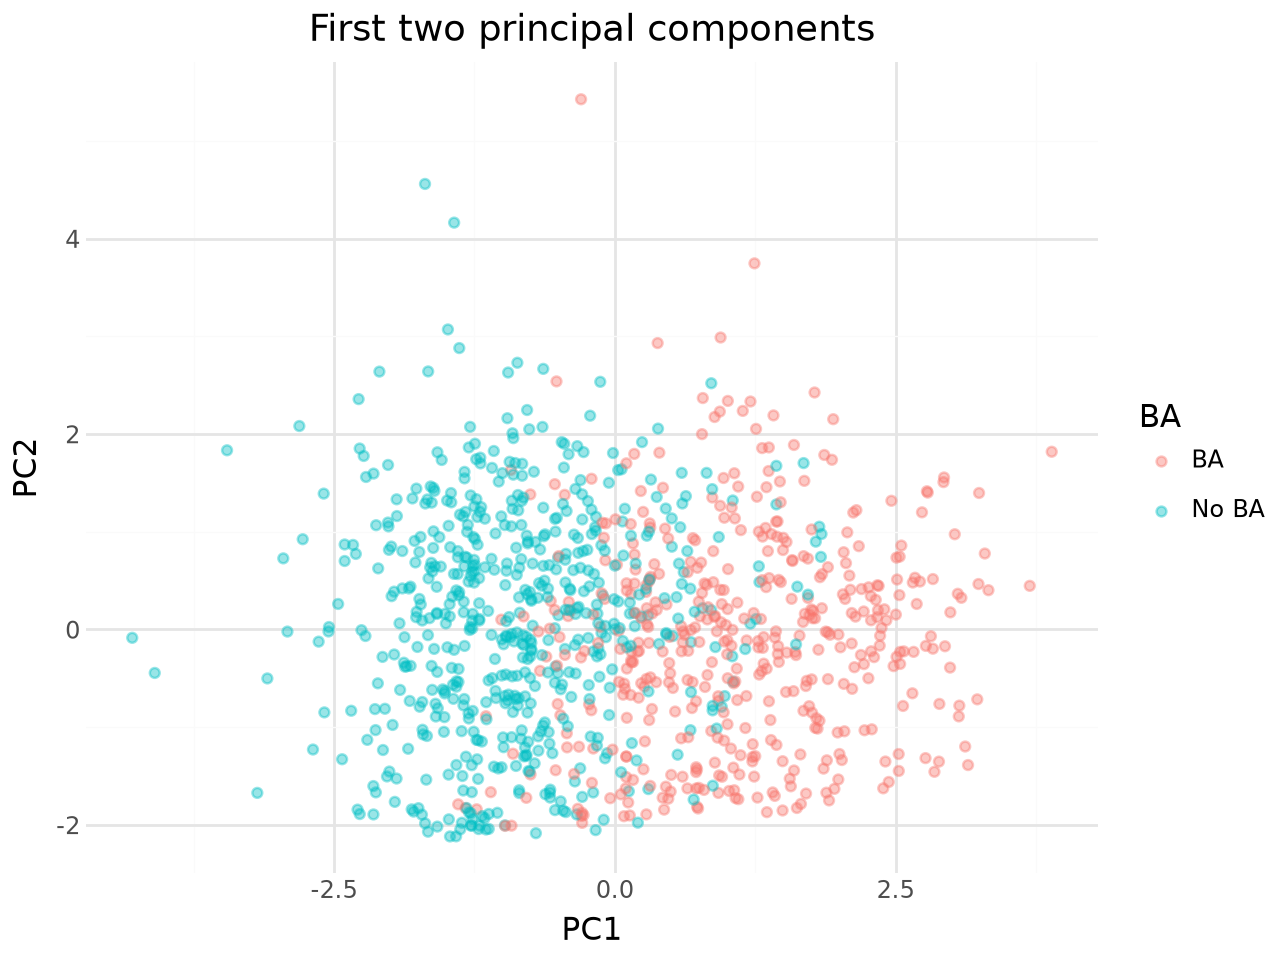

In [11]:
scores = pca.transform(X)
plot_df = work.copy()
plot_df["PC1"] = scores[:, 0]
plot_df["PC2"] = scores[:, 1]
plot_df["BA"] = np.where(plot_df["ba_binary"] == 1, "BA", "No BA")

(
    ggplot(plot_df, aes("PC1", "PC2", color="BA"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(x="PC1", y="PC2", title="First two principal components")
)


## 7. A linear model for PC1

PC1 is the dependent variable. `ba_binary` is the independent variable: 1 is a BA, 0 is not.

This is an OLS model. The coefficient on `ba_binary` is the expected difference in PC1 between a person with a BA and a person without one.


In [15]:
import statsmodels.formula.api as smf

ols_lm1 = smf.ols('PC1 ~ ba_binary', data=plot_df).fit()
print(ols_lm1.summary())

                            OLS Regression Results                            
Dep. Variable:                    PC1   R-squared:                       0.508
Model:                            OLS   Adj. R-squared:                  0.508
Method:                 Least Squares   F-statistic:                     1090.
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          9.80e-165
Time:                        10:12:26   Log-Likelihood:                -1453.9
No. Observations:                1056   AIC:                             2912.
Df Residuals:                    1054   BIC:                             2922.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.8650      0.039    -21.911      0.0

For participants with a BA, they are estimated to have a higher socioeconomic status by 1.96 points on average than those who do not have a BA.

## 8. A logit model for a BA

`ba_binary` is now the dependent variable, and PC1 and PC2 are the independent variables. `ba_binary` is coded 0 or 1, so we fit a logit.

The coefficient is the expected change in the log odds of having a BA. Exponentiating it gives the factor by which the odds change.


In [16]:
logit_lm1 = smf.logit('ba_binary ~ PC1 + PC2', data=plot_df).fit()
print(logit_lm1.summary())

Optimization terminated successfully.
         Current function value: 0.340435
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              ba_binary   No. Observations:                 1056
Model:                          Logit   Df Residuals:                     1053
Method:                           MLE   Df Model:                            2
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.5037
Time:                        10:15:00   Log-Likelihood:                -359.50
converged:                       True   LL-Null:                       -724.43
Covariance Type:            nonrobust   LLR p-value:                3.259e-159
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3769      0.095     -3.972      0.000      -0.563      -0.191
PC1            2.0936      0.

In [17]:
from marginaleffects import avg_comparisons, comparisons

avg_comparisons(logit_lm1, variables='PC1')

term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""PC1""","""+1""",0.221438,0.002664,83.113416,0.0,inf,0.21621,0.226666


In [18]:
avg_comparisons(logit_lm1, variables='PC2')

term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""PC2""","""+1""",-0.041696,0.009061,-4.601652,0.000005,17.698419,-0.059476,-0.023916


Using average marginal effects, with every unit increase of socioeconomic status (PC1), the likelihood of a person obtaining a BA increases by 22.1 percentage points on average. And based on PC2, for older people who have more children, the likelihood of obtaining a BA decreases by 4.1 percentage points on average. 

# Independent exercise

Use `happy_bin` as the dependent variable. Build the components from `income_cont`, `prestg10`, `educ`, `age`, and the four cultural-participation indicators (`binary_lvmus`, `binary_artxbt`, `binary_movie`, `binary_creat`). Leave `happy_bin` out of the PCA.

1. Scale each variable to mean 0 and SD 1, then fit a PCA.
2. Print the proportion of variance and the cumulative proportion.
3. Draw a scree plot with `plotnine` and decide how many components to keep.
4. Print the loadings and describe the first two components.
5. Scatter PC1 against PC2, coloured by happiness.
6. Fit a logit of `happy_bin` on the components you kept, and interpret the coefficients.


In [23]:
# Your answer here

cols2 = ["income_cont", "prestg10", "educ", "biokids", "age", "binary_lvmus", "binary_artxbt", "binary_movie", "binary_creat"]
work2 = df.dropna(subset=cols2).copy()
work2[cols2].describe().round(1)

,income_cont,prestg10,educ,biokids,age,binary_lvmus,binary_artxbt,binary_movie,binary_creat
count,1056.0,1056.0,1056.0,1056.0,1056.0,1056.0,1056.0,1056.0,1056.0
mean,86222.1,46.8,14.9,1.6,50.9,0.3,0.2,0.3,0.2
std,72378.7,13.3,2.7,1.5,17.3,0.5,0.4,0.4,0.4
min,500.0,17.0,2.0,0.0,18.0,0.0,0.0,0.0,0.0
25%,32500.0,36.0,13.0,0.0,36.0,0.0,0.0,0.0,0.0
50%,67500.0,47.0,15.0,2.0,51.0,0.0,0.0,0.0,0.0
75%,120000.0,59.0,16.0,2.0,66.0,1.0,0.0,1.0,0.0
max,250000.0,80.0,20.0,11.0,89.0,1.0,1.0,1.0,1.0


In [36]:
Y = StandardScaler().fit_transform(work2[cols2])
pca2 = PCA().fit(Y)

prop2 = pca2.explained_variance_ratio_
print(pd.DataFrame({
    "Standard deviation": pca2.explained_variance_ ** 0.5,
    "Proportion of variance": prop2,
    "Cumulative proportion": prop2.cumsum(),
}, index=["PC1a", "PC2a", "PC3a", "PC4a", "PC5a", "PC6a", "PC7a", "PC8a", "PC9a"]).T.round(3))

                         PC1a   PC2a   PC3a   PC4a   PC5a   PC6a   PC7a  \
Standard deviation      1.558  1.306  1.119  0.943  0.848  0.790  0.725   
Proportion of variance  0.269  0.189  0.139  0.099  0.080  0.069  0.058   
Cumulative proportion   0.269  0.459  0.598  0.697  0.776  0.846  0.904   

                         PC8a   PC9a  
Standard deviation      0.688  0.626  
Proportion of variance  0.052  0.043  
Cumulative proportion   0.957  1.000  


PC1 accounts for 26.9 of the variance. With PC2, they account for 45.9 of the variance. With PC3, they accoutn for 59.8 of the variance.

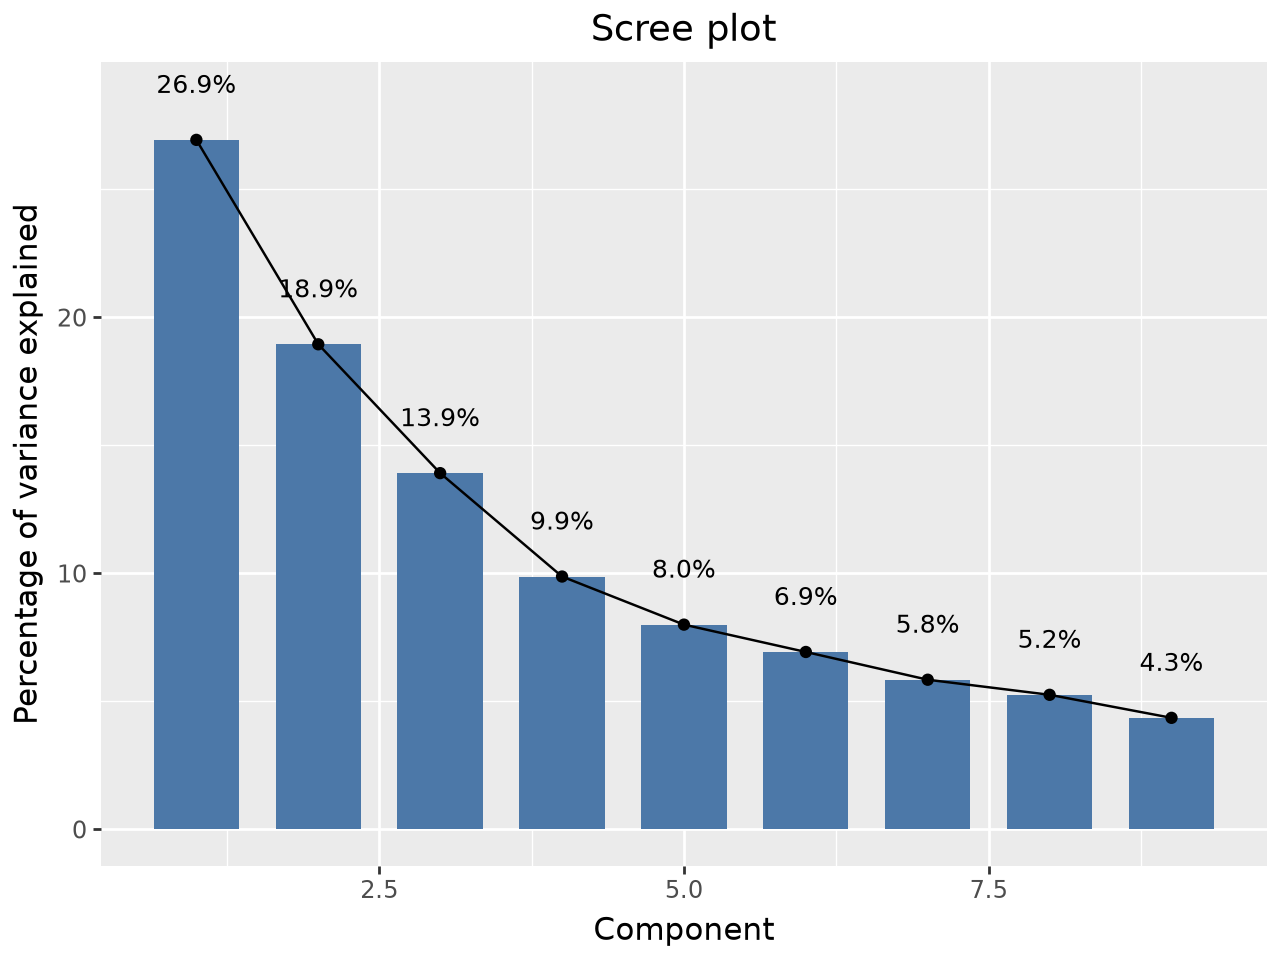

In [34]:
# SCREE

scree2 = pd.DataFrame({
    "component": range(1, 10),
    "percent": pca2.explained_variance_ratio_ * 100,
})
scree2["label"] = scree2["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree2, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(x="Component", y="Percentage of variance explained", title="Scree plot")
)

In [47]:
loadings2 = pd.DataFrame(
    pca2.components_.T,
    index=cols2,
    columns=["PC1a", "PC2a", "PC3a", "PC4a", "PC5a", "PC6a", "PC7a", "PC8a", "PC9a"],
)
print(loadings2.round(3))

                PC1a   PC2a   PC3a   PC4a   PC5a   PC6a   PC7a   PC8a   PC9a
income_cont    0.232  0.479 -0.046  0.375  0.091  0.696 -0.284 -0.028 -0.006
prestg10       0.280  0.525  0.047 -0.054  0.173 -0.406  0.159 -0.645  0.079
educ           0.332  0.470 -0.142 -0.172 -0.002 -0.268  0.135  0.722 -0.084
biokids       -0.105  0.005  0.713  0.368  0.439 -0.033  0.332  0.202  0.015
age           -0.023  0.205  0.662 -0.414 -0.481  0.067 -0.310 -0.023 -0.121
binary_lvmus   0.489 -0.224  0.125  0.140 -0.311  0.006  0.080  0.053  0.755
binary_artxbt  0.459 -0.230  0.034 -0.236 -0.084  0.374  0.583 -0.131 -0.419
binary_movie   0.409 -0.244  0.068  0.509 -0.172 -0.364 -0.352 -0.020 -0.472
binary_creat   0.357 -0.264  0.086 -0.432  0.636  0.038 -0.446  0.028  0.063


PC1a loads on whether the respondent went to a live music show, went to an art exhibition, created art and watched a movie. It can be assumed to be measuring participation in cultural activities. PC2a loads on income, occupational prestige and education, hence it is likely measuring socioeconomic status. PC3a loads on number of children and age, likely measuring type of family unit.

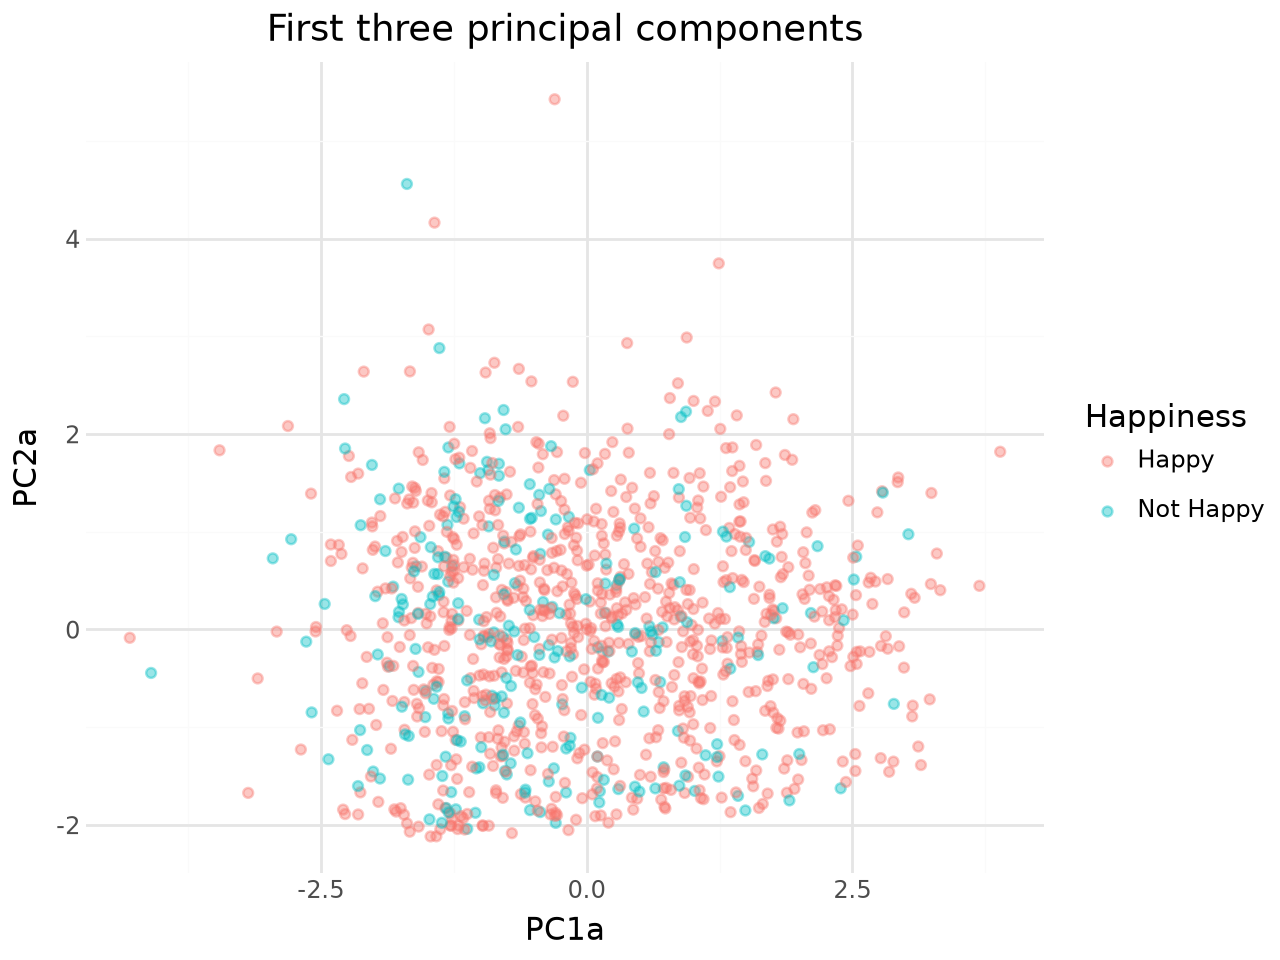

In [56]:
scores2 = pca2.transform(Y)
plot_df = work2.copy()
plot_df["PC1a"] = scores[:, 0]
plot_df["PC2a"] = scores[:, 1]
plot_df["PC3a"] = scores[:, 2]
plot_df["Happiness"] = np.where(plot_df["happy_bin"] == 1, "Happy", "Not Happy")

(
    ggplot(plot_df, aes("PC1a", "PC2a", color="Happiness"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(x="PC1a", y="PC2a", title="First three principal components")
)

In [57]:
logit_lm2 = smf.logit('happy_bin ~ PC1a + PC2a + PC3a', data=plot_df).fit()
print(logit_lm2.summary())

Optimization terminated successfully.
         Current function value: 0.512169
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              happy_bin   No. Observations:                 1056
Model:                          Logit   Df Residuals:                     1052
Method:                           MLE   Df Model:                            3
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                 0.03598
Time:                        10:59:47   Log-Likelihood:                -540.85
converged:                       True   LL-Null:                       -561.04
Covariance Type:            nonrobust   LLR p-value:                 8.900e-09
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.3157      0.079     16.737      0.000       1.162       1.470
PC1a           0.3165      0.

In [58]:
avg_comparisons(logit_lm2, variables='PC1a')

term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""PC1a""","""+1""",0.05289,0.009731,5.435321,6.7972e-8,23.810493,0.033796,0.071984


In [59]:
avg_comparisons(logit_lm2, variables='PC2a')

term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""PC2a""","""+1""",0.015306,0.011248,1.360761,0.173881,2.52383,-0.006765,0.037378


In [60]:
avg_comparisons(logit_lm2, variables='PC3a')

term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""PC3a""","""+1""",-0.047945,0.014785,-3.242864,0.001221,9.678261,-0.076956,-0.018934


Using average marginal effects, participants who participate in one more unit of cultural activity is expected to experience more happiness by 5.3 percentage points on average. 

From the average marginal effects of PC2a, with each unit increase in socioeconomic status, the participant is 1.5 percentage points more happiness on average. However, as the p-value for PC2a is not statistically significant, we can conclude that socioeconomic status does not reliably predict happiness levels.

From the average marginal effects of PC3a, participants of older age with having more children are expected to report lower happiness levels by 4.8 percentage points.